# Assignment 02: Generative Adversarial Network

In this assignment you implement a generative adversarial network (GAN) and train it on the same data as in Assignment 01, a small subset of MNIST: the digits 0, 1, 2, 3, 4 as gray images of 32 x 32 pixels, with 100 training images and 1000 test images per digit. The images come without labels.

**Do not modify this notebook.** It runs the code that you write, measures the trained generator, and saves the results.

You write the files in the `code` folder:

| File | What you write |
|---|---|
| `code/myinfo.py` | your name and student ID |
| `code/mymodel.py` | the GAN: generator, discriminator |
| `code/myoptim.py` | batch size, number of epochs, optimizers |
| `code/mytrain.py` | loss functions, training for one epoch |
| `code/mysample.py` | generation of new images |

Every part to write is marked with `TODO`, and the docstring of each function specifies its inputs and outputs. Keep these interfaces unchanged.

The files in the `util` folder are provided; do not modify them:

| File | What it provides |
|---|---|
| `util/data.py` | `get_dataset("train")` and `get_dataset("test")`: the training and the test images |
| `util/result.py` | `evaluate`: FID of the trained generator on the test images; `save`: writes it to a file |

The data files in the `data` folder are created by `util/prepare_data_mnist.py`.

Run all the cells from top to bottom (*Restart* and *Run All*). The notebook saves:

| File | Content |
|---|---|
| `train/loss.png`, `train/progress.png`, `train/model.pt` | training curves, images generated during the training, trained generator and discriminator |
| `sample/sample.png` | images generated by the trained generator |
| `result/interpolation.png` | images generated along lines of the latent space |
| `result/result_<student ID>_<name>.csv` | FID |

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# The notebook is in the project folder, next to the folders code, util, data
ROOT = Path.cwd()
assert (ROOT / "code").is_dir() and (ROOT / "util").is_dir(), (
    f"run this notebook from the project folder, which contains code and util (now in {ROOT})")

# Make the files of code (yours) and util (provided) importable
for folder in ("code", "util"):
    if str(ROOT / folder) not in sys.path:
        sys.path.insert(0, str(ROOT / folder))

# Folders for the files saved by the notebook
TRAIN_DIR, SAMPLE_DIR, RESULT_DIR = ROOT / "train", ROOT / "sample", ROOT / "result"
for folder in (TRAIN_DIR, SAMPLE_DIR, RESULT_DIR):
    folder.mkdir(exist_ok=True)

SEED = 0
torch.manual_seed(SEED)

# GPU of NVIDIA (cuda) or of an Apple silicon Mac (mps) if there is one, else the CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"torch   : {torch.__version__}")
print(f"device  : {device}")
print(f"project : {ROOT}")

torch   : 2.15.0+cu132
device  : cuda
project : /nas2/users/hong/class/neural-network/2026/project/project-02


In [2]:
# Helper functions and colors for the figures

BLUE, ORANGE = "#2a78d6", "#eb6834"                      # data: first and second curve
GRAY, GRID, INK = "#c3c2b7", "#e1e0d9", "#52514e"        # context, grid lines, text
MUTED = "#898781"                                        # reference values


def to_grid(images, num_cols):
    # Tile images of shape (N, 1, H, W) into one image with num_cols columns.
    images = images.detach().cpu().float()
    height, width = images.shape[-2:]
    images = images.reshape(-1, num_cols, height, width)
    return images.permute(0, 2, 1, 3).reshape(-1, num_cols * width)


def show_grid(ax, images, num_cols, title):
    ax.imshow(to_grid(images, num_cols), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")


def style_axes(ax):
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRAY)
    ax.tick_params(color=GRAY, labelcolor=INK)


def mark_value(ax, value, name):
    # Horizontal line at a reference value, with its name at the right end.
    ax.axhline(value, color=MUTED, linewidth=1, zorder=1.5)
    ax.annotate(name, xy=(1, value), xycoords=("axes fraction", "data"), xytext=(-3, 3),
                textcoords="offset points", ha="right", va="bottom", color=INK, fontsize=9)


def save_figure(fig, path):
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Student information

`code/myinfo.py`

In [3]:
from myinfo import get_info

info = get_info()
assert info["name"] and info["student_id"], "fill in your name and student ID in code/myinfo.py"

print(f"name       : {info['name']}")
print(f"student ID : {info['student_id']}")

name       : Gildong Hong
student ID : 20260000


## 2. Data

`util/data.py` (provided) gives the training and the test images. The training images are read in mini-batches with the batch size from `code/myoptim.py`: every batch of `train_loader` is a tensor of images of shape `(B, 1, 32, 32)` with values in `[0, 1]`. There are no labels.

In [4]:
from data import get_dataset
from myoptim import BATCH_SIZE, NUM_EPOCHS

train_dataset = get_dataset("train")
test_dataset = get_dataset("test")

# the training images are reshuffled at every epoch
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

image_shape = tuple(train_dataset.images.shape[1:])

print(f"training images : {len(train_dataset)} ({len(train_loader)} batches of {BATCH_SIZE})")
print(f"test images     : {len(test_dataset)}")
print(f"image           : shape {image_shape}, values in "
      f"[{train_dataset.images.min().item():.0f}, {train_dataset.images.max().item():.0f}]")

training images : 500 (8 batches of 64)
test images     : 5000
image           : shape (1, 32, 32), values in [0, 1]


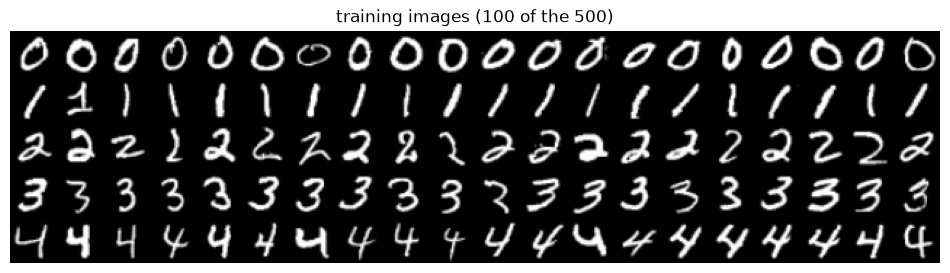

In [5]:
# One training image out of 5
examples = train_dataset.images[::5]

fig, ax = plt.subplots(figsize=(12, 3.2))
show_grid(ax, examples, 20, f"training images ({len(examples)} of the {len(train_dataset)})")
plt.show()

## 3. Model

`code/mymodel.py`

The generator turns latent variables `z` of shape `(B, latent_dim)` into images of shape `(B, 1, 32, 32)` with values in `[0, 1]`. The discriminator gives one logit per image, of shape `(B,)`: `D(x) = sigmoid(logit)` is the probability that the image `x` is real.

In [6]:
from mymodel import Discriminator, Generator

generator = Generator().to(device)
discriminator = Discriminator().to(device)
num_parameters_g = sum(p.numel() for p in generator.parameters())
num_parameters_d = sum(p.numel() for p in discriminator.parameters())

print(generator)
print(discriminator)
print(f"latent dimension     : {generator.latent_dim}")
print(f"number of parameters : {num_parameters_g:,} (generator), {num_parameters_d:,} (discriminator)")

Generator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=1024, bias=True)
    (3): Sigmoid()
  )
)
Discriminator(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=400, bias=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Linear(in_features=400, out_features=1, bias=True)
  )
)
latent dimension     : 64
number of parameters : 436,624 (generator), 410,401 (discriminator)


In [7]:
# Check the interface of the two networks on a few images

x = test_dataset.images[:8].to(device)
z = torch.randn(8, generator.latent_dim, device=device)

with torch.no_grad():
    fake = generator(z)
    real_logits = discriminator(x)
    fake_logits = discriminator(fake)

assert generator.latent_dim >= 2, "latent_dim must be at least 2"
assert fake.shape == x.shape, f"generator: output has shape {tuple(fake.shape)}, expected {tuple(x.shape)}"
assert 0 <= fake.min() and fake.max() <= 1, "generator: the values of the images must be in [0, 1]"
assert real_logits.shape == (8,), f"discriminator: output has shape {tuple(real_logits.shape)}, expected (8,)"
assert fake_logits.shape == (8,), f"discriminator: output has shape {tuple(fake_logits.shape)}, expected (8,)"

print("the generator and the discriminator have the expected interface")

the generator and the discriminator have the expected interface


## 4. Optimizers

`code/myoptim.py`

In [8]:
from myoptim import get_optimizers

optimizer_g, optimizer_d = get_optimizers(generator, discriminator)

print(f"batch size       : {BATCH_SIZE}")
print(f"number of epochs : {NUM_EPOCHS}")
print(f"optimizer of the generator     : {optimizer_g}")
print(f"optimizer of the discriminator : {optimizer_d}")

batch size       : 64
number of epochs : 400
optimizer of the generator     : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.5, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0
)
optimizer of the discriminator : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.5, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0
)


## 5. Training

`code/mytrain.py`

The two loss functions are first checked on two cases whose values are known:

| Discriminator | Logits | `discriminator_loss` | `generator_loss` |
|---|---|---|---|
| undecided: `D = 1/2` for every image | 0 for every image | log 4 | log 2 |
| sure and right: `D(x)` close to 1, `D(G(z))` close to 0 | 10 for real images, -10 for generated images | close to 0 | close to 10 |

In [9]:
from mytrain import discriminator_loss, generator_loss

zeros = torch.zeros(8, device=device)
high, low = torch.full((8,), 10.0, device=device), torch.full((8,), -10.0, device=device)

checks = [
    ("discriminator_loss, logits 0", discriminator_loss(zeros, zeros), math.log(4)),
    ("generator_loss, logits 0", generator_loss(zeros), math.log(2)),
    ("discriminator_loss, logits 10 (real) and -10 (generated)",
     discriminator_loss(high, low), 2 * math.log1p(math.exp(-10))),
    ("generator_loss, logits -10", generator_loss(low), math.log1p(math.exp(10))),
]

for name, value, expected in checks:
    assert torch.is_tensor(value) and value.shape == (), f"{name}: the loss must be a scalar tensor"
    assert abs(value.item() - expected) < 1e-3, f"{name}: got {value.item():.4f}, expected {expected:.4f}"
    print(f"{name:58s}: {value.item():7.4f}")

print("the loss functions give the expected values")

discriminator_loss, logits 0                              :  1.3863
generator_loss, logits 0                                  :  0.6931
discriminator_loss, logits 10 (real) and -10 (generated)  :  0.0001
generator_loss, logits -10                                : 10.0000
the loss functions give the expected values


The GAN is trained for `NUM_EPOCHS` epochs. To follow the generator, images are generated from the same 20 latent variables at six epochs of the training.

In [10]:
from mytrain import train_one_epoch

TERMS = ("loss_d", "loss_g", "d_real", "d_fake")
history = {term: [] for term in TERMS}

# Latent variables and epochs of the images that follow the generator
fixed_z = torch.randn(20, generator.latent_dim, device=device)
progress_epochs = sorted({max(1, round(NUM_EPOCHS * k / 5)) for k in range(6)})
progress = {}

for epoch in range(1, NUM_EPOCHS + 1):
    values = train_one_epoch(generator, discriminator, optimizer_g, optimizer_d, train_loader, device)
    for term in TERMS:
        history[term].append(float(values[term]))

    if epoch in progress_epochs:
        generator.eval()
        with torch.no_grad():
            progress[epoch] = generator(fixed_z).cpu()
        generator.train()

    if epoch == 1 or epoch == NUM_EPOCHS or epoch % max(1, NUM_EPOCHS // 20) == 0:
        print(f"epoch {epoch:4d}/{NUM_EPOCHS} | loss_d {values['loss_d']:6.3f}, loss_g {values['loss_g']:6.3f}"
              f" | D(x) {values['d_real']:.2f}, D(G(z)) {values['d_fake']:.2f}")

torch.save({"generator": generator.state_dict(), "discriminator": discriminator.state_dict()},
           TRAIN_DIR / "model.pt")

epoch    1/400 | loss_d  0.953, loss_g  1.716 | D(x) 0.51, D(G(z)) 0.23
epoch   20/400 | loss_d  0.612, loss_g  2.009 | D(x) 0.67, D(G(z)) 0.18
epoch   40/400 | loss_d  0.383, loss_g  2.197 | D(x) 0.82, D(G(z)) 0.15
epoch   60/400 | loss_d  0.626, loss_g  1.285 | D(x) 0.84, D(G(z)) 0.33
epoch   80/400 | loss_d  0.524, loss_g  1.215 | D(x) 0.90, D(G(z)) 0.33
epoch  100/400 | loss_d  0.375, loss_g  1.573 | D(x) 0.92, D(G(z)) 0.24
epoch  120/400 | loss_d  0.290, loss_g  2.088 | D(x) 0.91, D(G(z)) 0.16
epoch  140/400 | loss_d  0.285, loss_g  2.521 | D(x) 0.90, D(G(z)) 0.14
epoch  160/400 | loss_d  0.215, loss_g  2.915 | D(x) 0.91, D(G(z)) 0.10
epoch  180/400 | loss_d  0.150, loss_g  3.234 | D(x) 0.94, D(G(z)) 0.07
epoch  200/400 | loss_d  0.292, loss_g  2.905 | D(x) 0.89, D(G(z)) 0.11
epoch  220/400 | loss_d  0.346, loss_g  2.698 | D(x) 0.88, D(G(z)) 0.14
epoch  240/400 | loss_d  0.379, loss_g  2.707 | D(x) 0.86, D(G(z)) 0.15
epoch  260/400 | loss_d  0.405, loss_g  3.053 | D(x) 0.85, D(G(z

Training curves. The gray lines mark the values for an undecided discriminator, `D = 1/2` for every image: log 4 for the discriminator loss and log 2 for the generator loss.

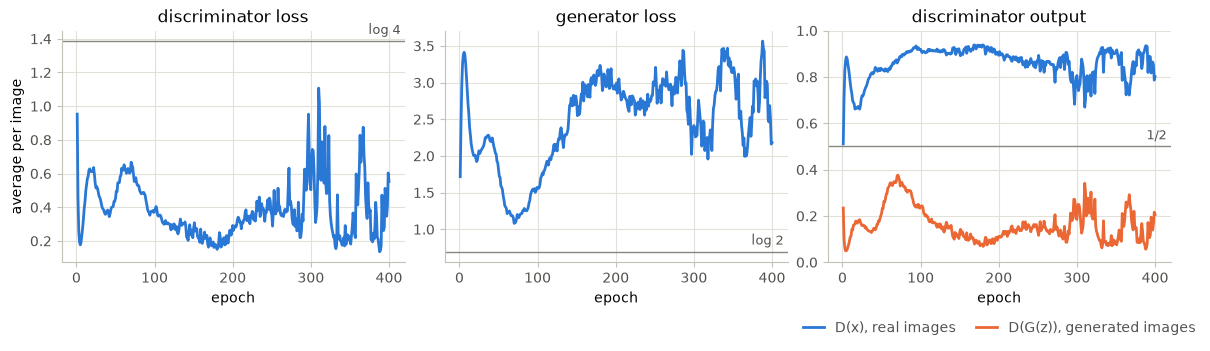

In [11]:
epochs = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)

axes[0].plot(epochs, history["loss_d"], color=BLUE, linewidth=2)
axes[0].set_title("discriminator loss")
mark_value(axes[0], math.log(4), "log 4")

axes[1].plot(epochs, history["loss_g"], color=BLUE, linewidth=2)
axes[1].set_title("generator loss")
mark_value(axes[1], math.log(2), "log 2")

axes[2].plot(epochs, history["d_real"], color=BLUE, linewidth=2, label="D(x), real images")
axes[2].plot(epochs, history["d_fake"], color=ORANGE, linewidth=2, label="D(G(z)), generated images")
axes[2].set_title("discriminator output")
axes[2].set_ylim(0, 1)
mark_value(axes[2], 0.5, "1/2")

for ax in axes:
    ax.set_xlabel("epoch")
    style_axes(ax)
axes[0].set_ylabel("average per image")

# the legend is below the axes, where it cannot hide the curves
axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False,
               labelcolor=INK, columnspacing=1.5, handlelength=1.5)
save_figure(fig, TRAIN_DIR / "loss.png")

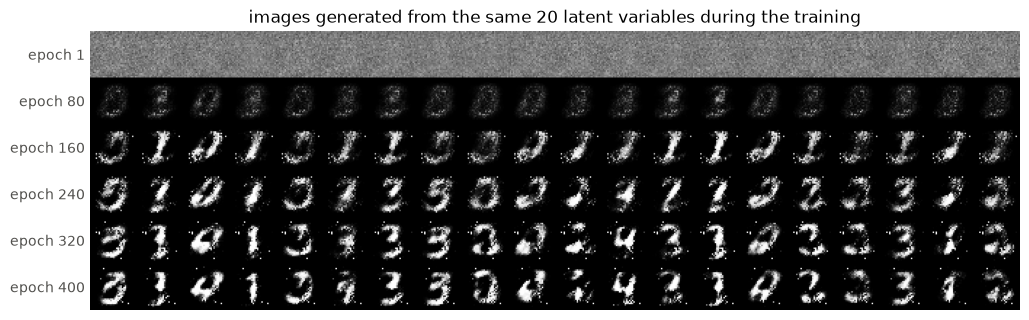

In [12]:
# One row per epoch, one column per latent variable
height = image_shape[-2]

fig, ax = plt.subplots(figsize=(12, 0.62 * len(progress) + 0.5))
ax.imshow(to_grid(torch.cat(list(progress.values())), len(fixed_z)), cmap="gray", vmin=0, vmax=1)
ax.set_title(f"images generated from the same {len(fixed_z)} latent variables during the training")
ax.set_xticks([])
ax.set_yticks([height * (row + 0.5) - 0.5 for row in range(len(progress))],
              [f"epoch {epoch}" for epoch in progress])
ax.tick_params(length=0, labelcolor=INK)
ax.spines[:].set_visible(False)
save_figure(fig, TRAIN_DIR / "progress.png")

## 6. Sampling

`code/mysample.py`

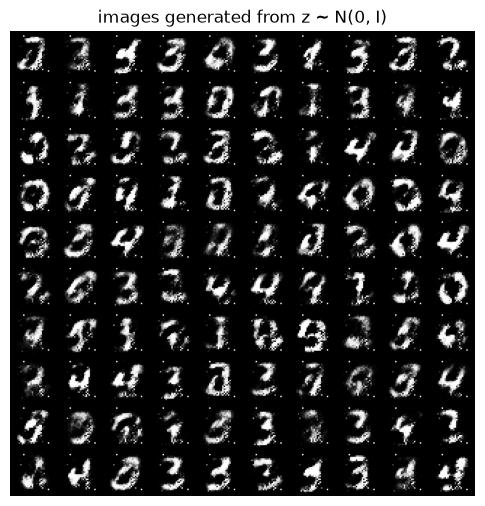

In [13]:
from mysample import sample

samples = sample(generator, 100, device)

assert samples.shape == (100, *image_shape), f"sample: output has shape {tuple(samples.shape)}"
assert 0 <= samples.min() and samples.max() <= 1, "sample: the values must be in [0, 1]"

fig, ax = plt.subplots(figsize=(6, 6.3))
show_grid(ax, samples, 10, "images generated from z ~ N(0, I)")
save_figure(fig, SAMPLE_DIR / "sample.png")

## 7. Interpolation

Images generated along lines of the latent space: each row goes from one latent variable (left) to another one (right) in 20 steps of equal length. The two ends of a row are drawn from `N(0, I)`.

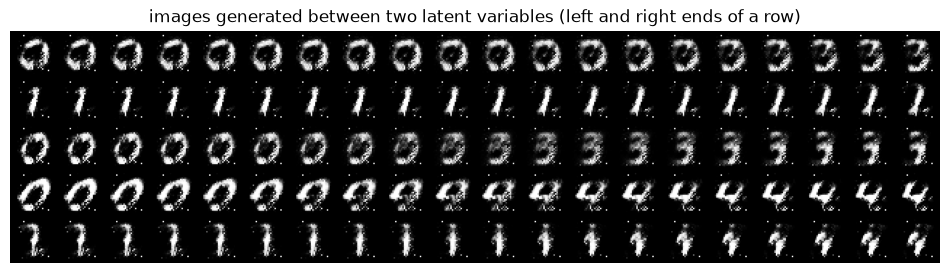

In [14]:
num_rows, num_steps = 5, 20

z_left = torch.randn(num_rows, 1, generator.latent_dim, device=device)
z_right = torch.randn(num_rows, 1, generator.latent_dim, device=device)
t = torch.linspace(0, 1, num_steps, device=device).view(1, num_steps, 1)
z = (1 - t) * z_left + t * z_right          # shape (num_rows, num_steps, latent_dim)

generator.eval()
with torch.no_grad():
    interpolations = generator(z.view(num_rows * num_steps, -1)).cpu()

fig, ax = plt.subplots(figsize=(12, 3.2))
show_grid(ax, interpolations, num_steps, "images generated between two latent variables (left and right ends of a row)")
save_figure(fig, RESULT_DIR / "interpolation.png")

## 8. Results

`util/result.py` (provided) measures the trained generator with the 5,000 test images. Lower is better.

- **FID**: distance between the distribution of 5,000 images generated by the generator and the distribution of the test images.

The first run downloads the network used by the FID (about 100 MB). The cell takes seconds with a GPU, but can take more than 10 minutes with a CPU.

In [15]:
from result import evaluate, save

result = evaluate(generator)
result_file = save(result, info)

print(f"name                 : {info['name']}")
print(f"student ID           : {info['student_id']}")
print(f"batch size           : {BATCH_SIZE}")
print(f"number of epochs     : {NUM_EPOCHS}")
print(f"latent dimension     : {generator.latent_dim}")
print(f"number of parameters : {num_parameters_g:,} (generator), {num_parameters_d:,} (discriminator)")
print()
print(f"FID                  : {result['fid']:.2f}")
print()
print(f"saved {result_file}")

/home/hong/class/neural-network/2026/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


name                 : Gildong Hong
student ID           : 20260000
batch size           : 64
number of epochs     : 400
latent dimension     : 64
number of parameters : 436,624 (generator), 410,401 (discriminator)

FID                  : 145.61

saved /nas2/users/hong/class/neural-network/2026/project/project-02/result/result_20260000_Gildong_Hong.csv
